# 07 · Cell-type-specific differential expression (pseudobulk)

**Why not a per-cell Wilcoxon test?** Cells from the same donor share genotype,
age, sampling and handling, so they are *not* independent replicates. Treating
thousands of cells as replicates makes tiny donor-specific differences
"significant" (pseudoreplication). Squair *et al.* (2021, *Nat Commun*) showed
that single-cell methods produce hundreds of false discoveries in data with no
true differences, whereas **pseudobulk** methods - summing counts per donor and
cell type and analysing them with bulk RNA-seq GLMs - control the FDR.

**Models** (per cell type, donors with ≥10 cells of that type, ≥3 donors per group):
* **edgeR quasi-likelihood** (`glmQLFit`, robust dispersion; primary)
* **DESeq2** Wald test with **apeglm** log-fold-change shrinkage (cross-check)
* design `~ sex + diagnosis`; genes pre-filtered with `filterByExpr`; TMM normalisation

**Sensitivity analyses** for the site-disease confounding described in Notebook 01:
`~ site + sex + diagnosis` and a Vanderbilt-only analysis.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from adjustText import adjust_text

from ipfatlas import pseudobulk
from ipfatlas.config import rscript, setup
from ipfatlas.plotting import COMPARTMENT_COLORS, figsize, panel_label, save_figure, set_style
from ipfatlas.utils import write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "07_de"
TAB = P.tables / "07_de"
C, D = cfg["contrast"], cfg["de"]
CASE, CTRL = C["case"], C["control"]
R = rscript(cfg)
WORK = P.interim / "pseudobulk"

adata = sc.read_h5ad(P.processed / "discovery_annotated.h5ad")
sub = adata[adata.obs["diagnosis"].isin([CASE, CTRL])].copy()
ct_comp = adata.obs.groupby("cell_type", observed=True)["compartment"].first()
del adata
sub

AnnData object with n_obs × n_vars = 101039 × 24723
    obs: 'library_id', 'donor_id', 'diagnosis', 'status', 'site', 'author_celltype', 'author_compartment', 'author_qc_pass', 'cohort', 'chemistry', 'sex', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier_counts', 'outlier_genes', 'outlier_top20', 'outlier_mito', 'outlier_hard', 'qc_fail', 'scDblFinder_score', 'scDblFinder_class', 'scDblFinder_doublet', 'scrublet_score', 'scrublet_doublet', 'S_score', 'G2M_score', 'phase', 'leiden_1.0', 'mk_proliferation', 'celltypist', 'celltypist_conf', 'compartment_l1', 'subcluster', 'cell_type', 'cell_type_reason', 'compartment', 'harmonised_celltype'
    var: 'gene_symbol', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_m

## 1. Pseudobulk aggregation

In [2]:
pb = pseudobulk.aggregate(sub, "cell_type", "donor_id", "diagnosis", covariates=["sex", "site"],
                          min_cells=D["min_cells_per_pseudobulk"])
index = pseudobulk.write_inputs(pb, WORK / "main_in", CASE, CTRL, min_donors=D["min_donors_per_group"])
write_table(index, TAB / "pseudobulk_samples_per_celltype", index=False)
index

,celltype,key,n_case,n_control,median_cells_per_donor,status
0,AT1,AT1,10,7,67,tested
1,AT2,AT2,11,9,214,tested
2,Transitional AT2,Transitional_AT2,6,4,28,tested
3,Aberrant basaloid,Aberrant_basaloid,7,1,26,skipped (too few donors)
4,Basal,Basal,11,2,45,skipped (too few donors)
5,Secretory (club/goblet),Secretory_club_goblet,12,7,74,tested
6,SCGB3A2+ secretory,SCGB3A2_secretory,12,8,118,tested
7,Ciliated,Ciliated,12,8,239,tested
8,Alveolar macrophages,Alveolar_macrophages,12,9,352,tested
9,SPP1hi macrophages,SPP1hi_macrophages,12,8,108,tested


## 2. edgeR-QL and DESeq2: `~ sex + diagnosis`

In [3]:
summary = pseudobulk.run_de(R, P.r_scripts / "pseudobulk_de.R", WORK / "main_in", WORK / "main_out",
                            covariates=["sex"], case=CASE, control=CTRL)
edger = pseudobulk.read_results(WORK / "main_out", "edgeR")
deseq = pseudobulk.read_results(WORK / "main_out", "DESeq2")
edger["significant"] = edger["FDR"] < D["fdr"]
edger["strong"] = edger["significant"] & (edger["logFC"].abs() > D["lfc"])
edger["compartment"] = edger["celltype"].map(ct_comp)
write_table(edger, TAB / "edgeR_IPF_vs_control_all_celltypes", index=False)
write_table(deseq, TAB / "DESeq2_IPF_vs_control_all_celltypes", index=False)
summary

04:43:46 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\pseudobulk_de.R J:\Portfolio_projects\Projects\scRNA\data\interim\pseudobulk\main_in J:\Portfolio_projects\Projects\scRNA\data\interim\pseudobulk\main_out sex IPF Control edgeR,DESeq2


04:47:15 | INFO | R finished: pseudobulk_de.R
[28/31] Alveolar fibroblasts             case=6 control=4 genes=1874
converting counts to integer mode
-- note: fitType='parametric', but the dispersion trend was not well captured by the
   function: y = a/x + b, and a local regression fit was automatically substituted.
   specify fitType='local' or 'mean' to avoid this message next time.
[29/31] Adventitial fibroblasts          case=8 control=4 genes=4266
converting counts to integer mode
-- note: fitType='parametric', but the dispersion trend was not well captured by the
   function: y = a/x + b, and a local regression fit was automatically substituted.
   specify fitType='local' or 'mean' to avoid this message next time.
[30/31] Smooth muscle                    case=9 control=5 genes=2147
converting counts to integer mode
[31/31] Pericytes                        case=6 control=3 genes=3032
There were 14 warnings (use warnings() to see them)
pseudobulk DE finished


04:47:15 | INFO | edgeR: 31 cell types, 159,087 gene tests


04:47:16 | INFO | DESeq2: 31 cell types, 159,087 gene tests


,celltype,key,n_case,n_control,n_genes_tested,design,edgeR_n_fdr05,edgeR_n_up,edgeR_n_down,DESeq2_n_fdr05
0,AT1,AT1,10,7,3325,~sex + condition,144,68,76,278
1,AT2,AT2,11,9,9361,~sex + condition,436,314,122,775
2,Transitional AT2,Transitional_AT2,6,4,4935,~sex + condition,207,122,85,308
3,Secretory (club/goblet),Secretory_club_goblet,12,7,6204,~sex + condition,717,210,507,927
4,SCGB3A2+ secretory,SCGB3A2_secretory,12,8,7563,~sex + condition,288,175,113,439
5,Ciliated,Ciliated,12,8,10611,~sex + condition,4,2,2,70
6,Alveolar macrophages,Alveolar_macrophages,12,9,10545,~sex + condition,217,141,76,443
7,SPP1hi macrophages,SPP1hi_macrophages,12,8,7832,~sex + condition,59,33,26,144
8,Interstitial macrophages,Interstitial_macrophages,12,9,7545,~sex + condition,20,15,5,126
9,Classical monocytes,Classical_monocytes,12,10,6981,~sex + condition,158,108,50,259


## 3. Agreement between edgeR and DESeq2

In [4]:
m = edger.merge(deseq, on=["celltype", "gene"], suffixes=("_edgeR", "_DESeq2"))
agree = m.groupby("celltype").apply(lambda d: pd.Series({
    "pearson_logFC": np.corrcoef(d["logFC"], d["log2FC"])[0, 1],
    "n_edgeR": int((d["FDR"] < 0.05).sum()),
    "n_DESeq2": int((d["padj"] < 0.05).sum()),
    "n_both": int(((d["FDR"] < 0.05) & (d["padj"] < 0.05)).sum()),
}), include_groups=False)
agree["jaccard"] = agree["n_both"] / (agree["n_edgeR"] + agree["n_DESeq2"] - agree["n_both"]).replace(0, np.nan)
write_table(agree.round(3), TAB / "edgeR_vs_DESeq2_agreement")
agree.round(3)

,pearson_logFC,n_edgeR,n_DESeq2,n_both,jaccard
celltype,,,,,
AT1,0.997,144.0,278.0,144.0,0.518
AT2,0.964,436.0,775.0,433.0,0.557
Adventitial fibroblasts,0.996,76.0,310.0,76.0,0.245
Aerocyte capillary EC,0.996,2.0,21.0,2.0,0.095
Alveolar fibroblasts,0.995,4.0,29.0,4.0,0.138
Alveolar macrophages,0.988,217.0,443.0,215.0,0.483
Arterial EC,0.996,98.0,147.0,95.0,0.633
B cells,0.994,0.0,0.0,0.0,NaN
CD4 T cells,0.913,0.0,0.0,0.0,NaN


## 4. Overview: DEGs per cell type

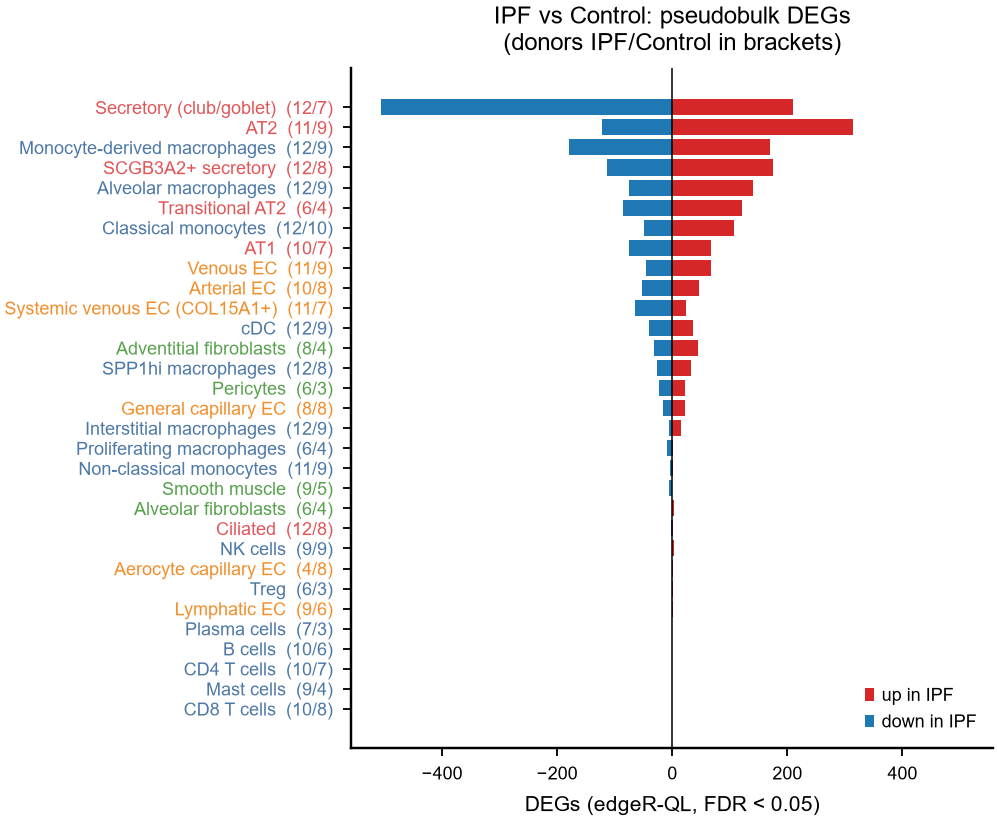

In [5]:
cnt = edger[edger["significant"]].groupby("celltype").agg(up=("logFC", lambda x: (x > 0).sum()),
                                                          down=("logFC", lambda x: (x < 0).sum()))
cnt = cnt.reindex(summary["celltype"]).fillna(0).astype(int)
cnt["total"] = cnt.sum(axis=1)
cnt = cnt.sort_values("total")
n_donors = summary.set_index("celltype")[["n_case", "n_control"]]

fig, ax = plt.subplots(figsize=figsize(95, 4 + 3.2 * len(cnt)))
y = np.arange(len(cnt))
ax.barh(y, cnt["up"], color="#D62728", label=f"up in {CASE}")
ax.barh(y, -cnt["down"], color="#1F77B4", label=f"down in {CASE}")
ax.set_yticks(y)
ax.set_yticklabels([f"{c}  ({n_donors.loc[c, 'n_case']}/{n_donors.loc[c, 'n_control']})" for c in cnt.index])
for t, c in zip(ax.get_yticklabels(), cnt.index):
    t.set_color(COMPARTMENT_COLORS.get(ct_comp.get(c), "black"))
ax.axvline(0, color="black", lw=0.5)
ax.set_xlabel(f"DEGs (edgeR-QL, FDR < {D['fdr']})")
ax.set_title(f"{CASE} vs {CTRL}: pseudobulk DEGs\n(donors {CASE}/{CTRL} in brackets)")
ax.legend(loc="lower right")
xmax = max(cnt["up"].max(), cnt["down"].max()) * 1.1
ax.set_xlim(-xmax, xmax)
save_figure(fig, "Fig3_deg_counts_per_celltype", FIG)
plt.show()

## 5. Volcano plots for the cell types with most DEGs

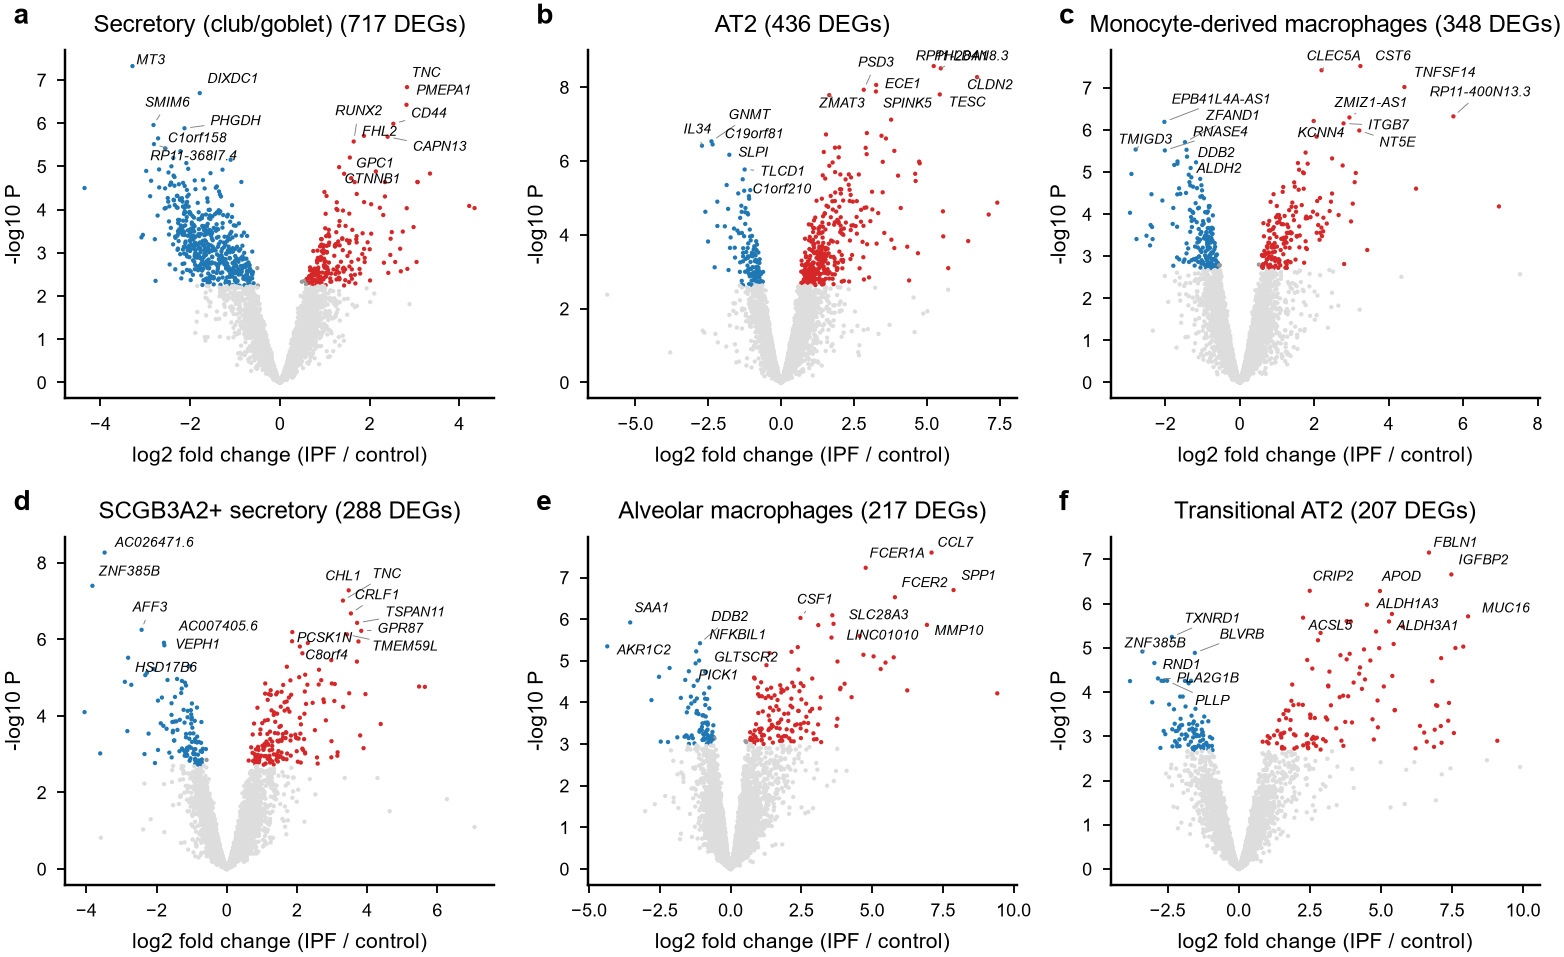

In [6]:
top_ct = cnt.sort_values("total", ascending=False).index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=figsize(183, 115))
for ax, ct in zip(axes.ravel(), top_ct):
    d = edger[edger["celltype"] == ct].copy()
    d["nlp"] = -np.log10(d["PValue"].clip(lower=1e-300))
    col = np.where(d["strong"] & (d["logFC"] > 0), "#D62728",
                   np.where(d["strong"] & (d["logFC"] < 0), "#1F77B4",
                            np.where(d["significant"], "#999999", "#DDDDDD")))
    ax.scatter(d["logFC"], d["nlp"], s=2, c=col, lw=0, rasterized=True)
    lab = pd.concat([d[d["strong"] & (d["logFC"] > 0)].nsmallest(8, "PValue"),
                     d[d["strong"] & (d["logFC"] < 0)].nsmallest(6, "PValue")])
    texts = [ax.text(r.logFC, r.nlp, r.gene, fontsize=4.5, style="italic") for r in lab.itertuples()]
    adjust_text(texts, ax=ax, arrowprops={"arrowstyle": "-", "lw": 0.3, "color": "grey"})
    ax.set_title(f"{ct} ({int(d['significant'].sum())} DEGs)")
    ax.set_xlabel("log2 fold change (IPF / control)")
    ax.set_ylabel("-log10 P")
for a, l in zip(axes.ravel(), "abcdef"):
    panel_label(a, l)
fig.tight_layout()
save_figure(fig, "Fig3_volcano_top_celltypes", FIG)
plt.show()

## 6. Shared vs cell-type-specific responses
Genes that are DE in many cell types point to tissue-wide programmes (e.g.
interferon, hypoxia) or residual ambient RNA; cell-type-specific DEGs are more
likely to reflect cell-intrinsic disease biology.

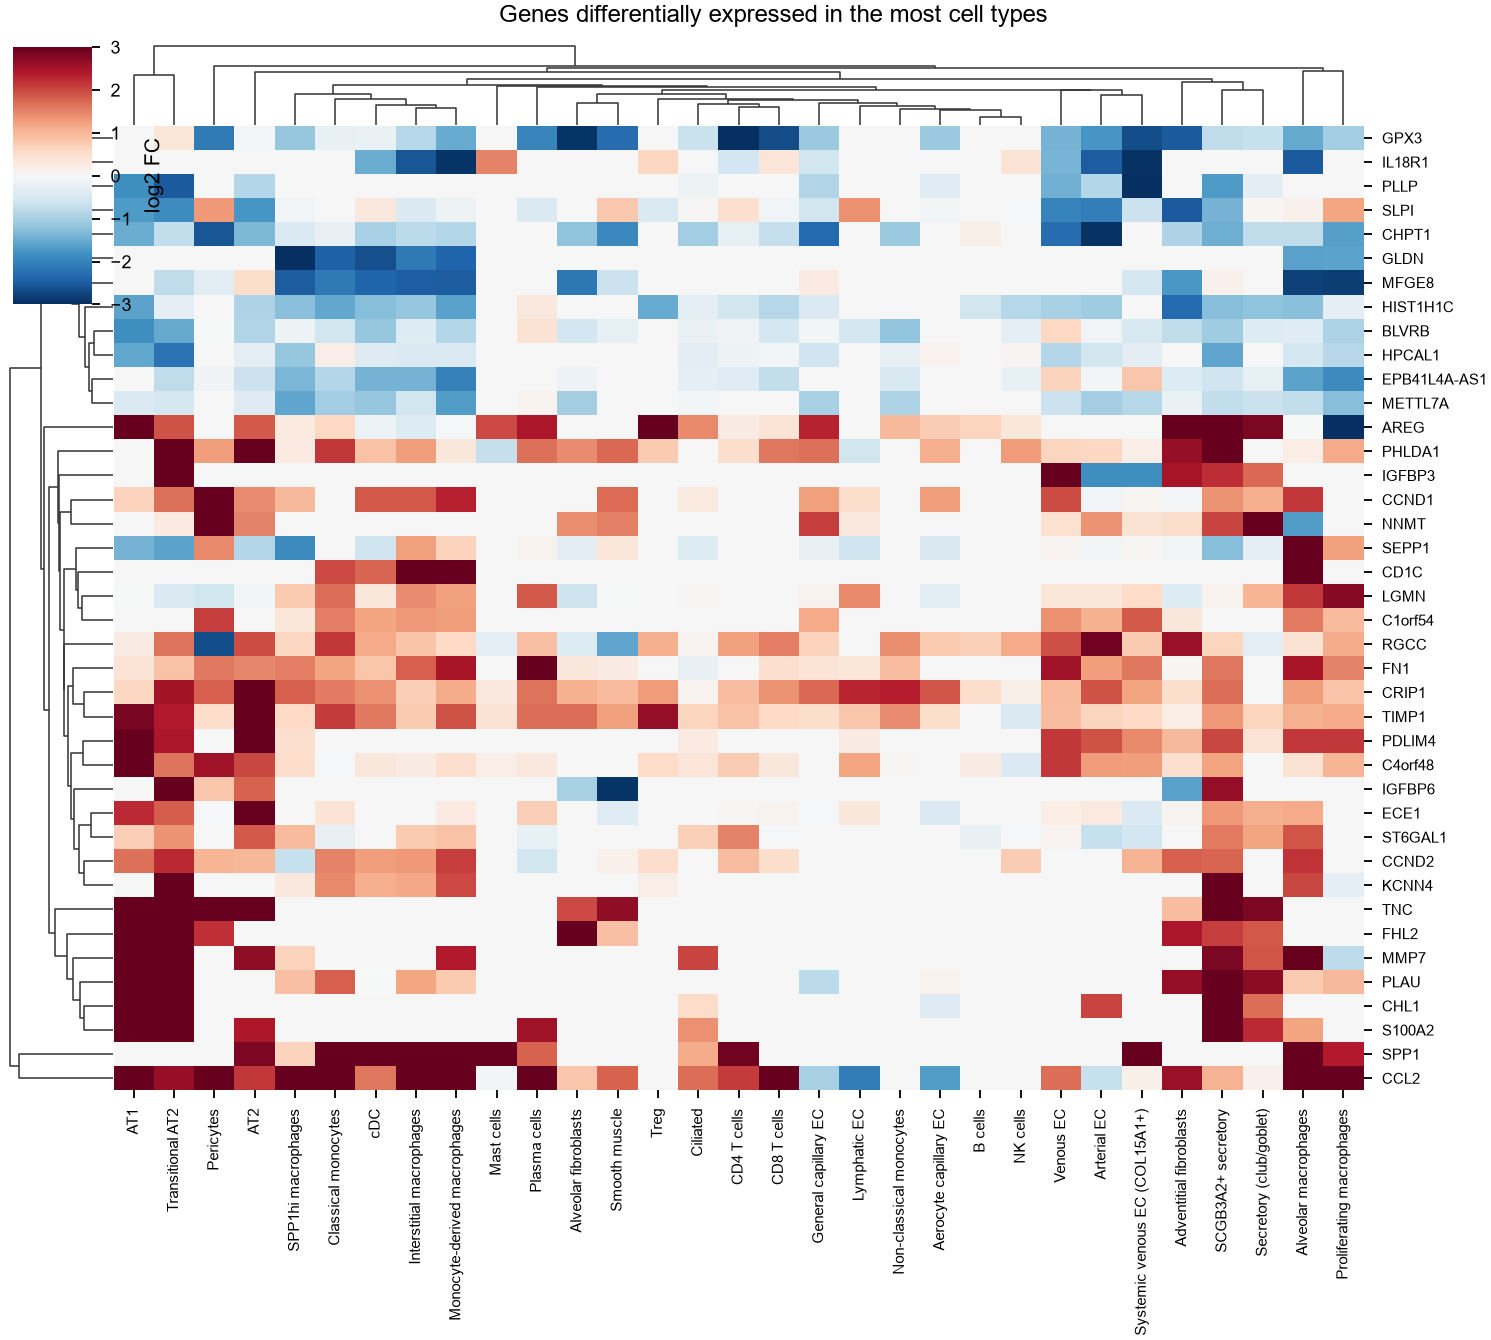

In [7]:
sig = edger[edger["strong"]]
n_ct = sig.groupby("gene")["celltype"].nunique().sort_values(ascending=False)
write_table(n_ct.rename("n_celltypes").to_frame(), TAB / "deg_recurrence_across_celltypes")
shared = n_ct.index[:40]
lfc = edger.pivot_table(index="gene", columns="celltype", values="logFC").reindex(shared)
fdr = edger.pivot_table(index="gene", columns="celltype", values="FDR").reindex(shared)
lfc = lfc.loc[:, lfc.notna().sum() > 0]
g = sns.clustermap(lfc.fillna(0), cmap="RdBu_r", center=0, vmin=-3, vmax=3, figsize=(7.2, 6.5),
                   linewidths=0, cbar_kws={"label": "log2 FC"}, xticklabels=True, yticklabels=True,
                   dendrogram_ratio=0.08)
g.ax_heatmap.tick_params(labelsize=5)
g.ax_heatmap.set_xlabel("")
g.ax_heatmap.set_ylabel("")
g.fig.suptitle("Genes differentially expressed in the most cell types", y=1.01, fontsize=8)
save_figure(g.fig, "S7_shared_degs_heatmap", FIG)
plt.show()

## 7. Sensitivity analyses for site confounding

In [8]:
pseudobulk.run_de(R, P.r_scripts / "pseudobulk_de.R", WORK / "main_in", WORK / "site_out",
                  covariates=["site", "sex"], case=CASE, control=CTRL, methods="edgeR")
site = pseudobulk.read_results(WORK / "site_out", "edgeR")

vu = sub[sub.obs["site"] == "Vanderbilt"]
pb_vu = pseudobulk.aggregate(vu, "cell_type", "donor_id", "diagnosis", covariates=["sex"], min_cells=D["min_cells_per_pseudobulk"])
pseudobulk.write_inputs(pb_vu, WORK / "vu_in", CASE, CTRL, min_donors=D["min_donors_per_group"])
pseudobulk.run_de(R, P.r_scripts / "pseudobulk_de.R", WORK / "vu_in", WORK / "vu_out",
                  covariates=["sex"], case=CASE, control=CTRL, methods="edgeR")
vuo = pseudobulk.read_results(WORK / "vu_out", "edgeR")


def concordance(a, b, name):
    mm = a.merge(b, on=["celltype", "gene"], suffixes=("", "_s"))
    rows = []
    for ct, d in mm.groupby("celltype"):
        s = d[d["FDR"] < 0.05]
        rows.append({"celltype": ct, "analysis": name, "n_main_DEGs": len(s),
                     "logFC_pearson_all": np.corrcoef(d["logFC"], d["logFC_s"])[0, 1],
                     "sign_agreement_main_DEGs": (np.sign(s["logFC"]) == np.sign(s["logFC_s"])).mean() if len(s) else np.nan,
                     "replicated_P05": ((s["PValue_s"] < 0.05) & (np.sign(s["logFC"]) == np.sign(s["logFC_s"]))).mean() if len(s) else np.nan})
    return pd.DataFrame(rows)


sens = pd.concat([concordance(edger, site, "~ site + sex + diagnosis"),
                  concordance(edger, vuo, "Vanderbilt only")])
write_table(sens.round(3), TAB / "de_sensitivity_site", index=False)
sens.pivot(index="celltype", columns="analysis", values="sign_agreement_main_DEGs").round(3)

04:47:28 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\pseudobulk_de.R J:\Portfolio_projects\Projects\scRNA\data\interim\pseudobulk\main_in J:\Portfolio_projects\Projects\scRNA\data\interim\pseudobulk\site_out site,sex IPF Control edgeR


04:49:03 | INFO | R finished: pseudobulk_de.R
[19/31] Plasma cells                     case=7 control=3 genes=5437
[20/31] Proliferating macrophages        case=6 control=4 genes=3690
[21/31] Monocyte-derived macrophages     case=12 control=9 genes=8983
[22/31] Aerocyte capillary EC            case=4 control=8 genes=4343
[23/31] General capillary EC             case=8 control=8 genes=6768
[24/31] Arterial EC                      case=10 control=8 genes=4842
[25/31] Venous EC                        case=11 control=9 genes=4617
[26/31] Systemic venous EC (COL15A1+)    case=11 control=7 genes=6110
[27/31] Lymphatic EC                     case=9 control=6 genes=2814
[28/31] Alveolar fibroblasts             case=6 control=4 genes=3087
[29/31] Adventitial fibroblasts          case=8 control=4 genes=6168
[30/31] Smooth muscle                    case=9 control=5 genes=2957
[31/31] Pericytes                        case=6 control=3 genes=3032
There were 15 warnings (use warnings() to see them)
p

04:49:03 | INFO | edgeR: 31 cell types, 195,599 gene tests


04:49:10 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\pseudobulk_de.R J:\Portfolio_projects\Projects\scRNA\data\interim\pseudobulk\vu_in J:\Portfolio_projects\Projects\scRNA\data\interim\pseudobulk\vu_out sex IPF Control edgeR


04:50:00 | INFO | R finished: pseudobulk_de.R
[23/29] Arterial EC                      case=6 control=5 genes=4543
[24/29] Venous EC                        case=7 control=6 genes=3191
[25/29] Systemic venous EC (COL15A1+)    case=6 control=5 genes=2616
[26/29] Lymphatic EC                     case=6 control=4 genes=1949
[27/29] Adventitial fibroblasts          case=3 control=3 genes=3734
[28/29] Smooth muscle                    case=5 control=3 genes=1916
[29/29] Pericytes                        case=3 control=3 genes=1431
Warning messages:
1: In sqrt(F) : NaNs produced
2: In sqrt(F) : NaNs produced
3: In sqrt(F) : NaNs produced
4: In sqrt(F) : NaNs produced
5: In sqrt(F) : NaNs produced
6: In sqrt(F) : NaNs produced
pseudobulk DE finished


04:50:01 | INFO | edgeR: 29 cell types, 152,536 gene tests


analysis,Vanderbilt only,~ site + sex + diagnosis
celltype,,
AT1,1.0,1.0
AT2,1.0,1.0
Adventitial fibroblasts,1.0,1.0
Aerocyte capillary EC,1.0,1.0
Alveolar fibroblasts,NaN,1.0
Alveolar macrophages,1.0,1.0
Arterial EC,1.0,1.0
B cells,NaN,NaN
CD4 T cells,NaN,NaN


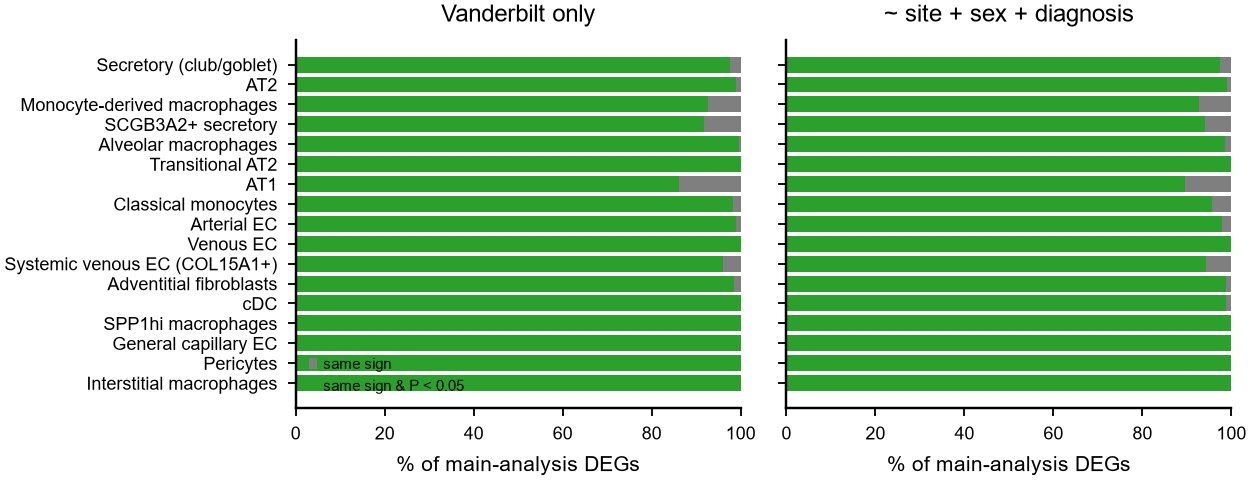

In [9]:
fig, axes = plt.subplots(1, 2, figsize=figsize(150, 60), sharey=True)
for ax, (name, d) in zip(axes, sens.groupby("analysis")):
    d = d.dropna(subset=["sign_agreement_main_DEGs"]).sort_values("n_main_DEGs")
    d = d[d["n_main_DEGs"] >= 10]
    ax.barh(d["celltype"], d["sign_agreement_main_DEGs"] * 100, color="#7F7F7F", label="same sign")
    ax.barh(d["celltype"], d["replicated_P05"] * 100, color="#2CA02C", label="same sign & P < 0.05")
    ax.set_xlim(0, 100)
    ax.set_xlabel("% of main-analysis DEGs")
    ax.set_title(name)
axes[0].legend(fontsize=5, loc="lower left")
fig.tight_layout()
save_figure(fig, "S7_de_site_sensitivity", FIG)
plt.show()